In [46]:
import pandas as pd
import numpy as np
import matplotlib as mlt
import seaborn as sns

In [47]:
df_train_raw=pd.read_csv('../data/train.csv')
df_train_raw.head()

,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800


In [48]:
df_train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   RENT_APPROVAL_DATE   150000 non-null  str    
 1   TOWN                 150000 non-null  str    
 2   BLOCK                150000 non-null  str    
 3   STREET               150000 non-null  str    
 4   FLAT_TYPE            150000 non-null  str    
 5   FLAT_MODEL           150000 non-null  str    
 6   FLOOR_AREA_SQM       150000 non-null  float64
 7   FURNISHED            150000 non-null  str    
 8   LEASE_COMMENCE_DATE  150000 non-null  int64  
 9   FEE                  150000 non-null  float64
 10  MONTHLY_RENT         150000 non-null  int64  
dtypes: float64(2), int64(2), str(7)
memory usage: 20.4 MB


---
## EDA plan (appended below your existing cells)

Goal: use `train.csv` + auxiliary Singapore datasets to predict `MONTHLY_RENT` for the rows in `test.csv`.

The cell below sets up a few extra imports/variables (`test`, `DATA_DIR`, `AUX_DIR`) that the steps after it rely on, reusing your `df_train_raw` as `train`.

In [49]:
# Bridge cell: extra imports + variables used by the EDA steps below
import matplotlib.pyplot as plt
from scipy.stats import skew

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

DATA_DIR = '../data'
AUX_DIR = f'{DATA_DIR}/auxiliary'

train = df_train_raw
test = pd.read_csv(f'{DATA_DIR}/test.csv')

print('train:', train.shape, ' test:', test.shape)

train: (150000, 11)  test: (50000, 10)


## 1. Schema & target sanity pass
Confirm dtypes, find zero-variance columns, confirm the real target.

In [50]:
print('--- columns only in train (i.e. the target) ---')
print(set(train.columns) - set(test.columns))
print()
print('--- nunique per column (train) ---')
print(train.nunique())
print()
zero_var = [c for c in train.columns if train[c].nunique() <= 1]
print('Zero-variance columns in train:', zero_var)

--- columns only in train (i.e. the target) ---
{'MONTHLY_RENT'}

--- nunique per column (train) ---
RENT_APPROVAL_DATE       51
TOWN                     26
BLOCK                  2720
STREET                 1146
FLAT_TYPE                11
FLAT_MODEL               20
FLOOR_AREA_SQM          156
FURNISHED                 1
LEASE_COMMENCE_DATE      57
FEE                       1
MONTHLY_RENT            608
dtype: int64

Zero-variance columns in train: ['FURNISHED', 'FEE']


## 2. Target distribution
Check skew/outliers to decide raw vs `log1p(MONTHLY_RENT)` modeling target.

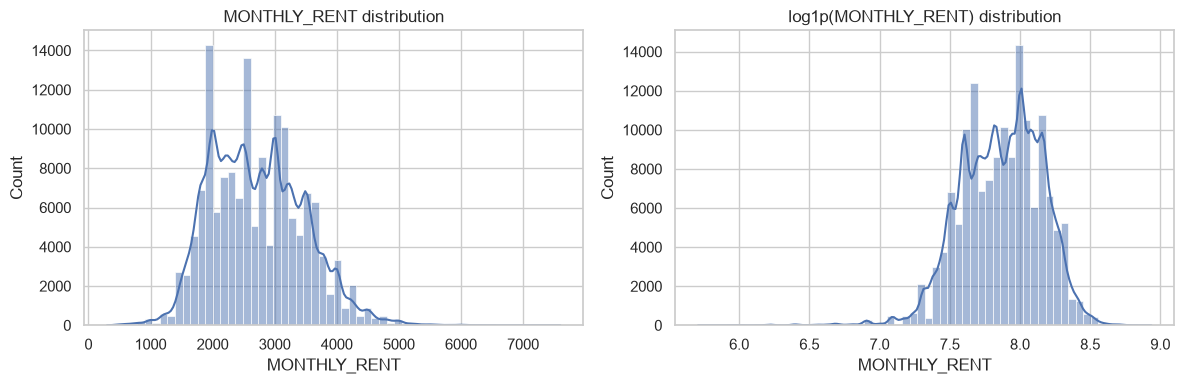

Skew (raw): 0.38639858991261883
Skew (log1p): -0.42366510796700646
count    150000.000000
mean       2719.036893
std         749.731096
min         300.000000
25%        2100.000000
50%        2700.000000
75%        3200.000000
max        7600.000000
Name: MONTHLY_RENT, dtype: float64


In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['MONTHLY_RENT'], bins=60, kde=True, ax=axes[0])
axes[0].set_title('MONTHLY_RENT distribution')

sns.histplot(np.log1p(train['MONTHLY_RENT']), bins=60, kde=True, ax=axes[1])
axes[1].set_title('log1p(MONTHLY_RENT) distribution')
plt.tight_layout()
plt.show()

print('Skew (raw):', skew(train['MONTHLY_RENT']))
print('Skew (log1p):', skew(np.log1p(train['MONTHLY_RENT'])))
print(train['MONTHLY_RENT'].describe())

## 3. Data-quality / train-vs-test consistency audit
This is the step that prevents silent bugs later: duplicate category encodings, casing mismatches, unseen categories, exact duplicate rows.

In [52]:
print('--- FLAT_TYPE value counts (train) ---')
print(train['FLAT_TYPE'].value_counts())
print()
print('--- FLAT_TYPE value counts (test) ---')
print(test['FLAT_TYPE'].value_counts())

--- FLAT_TYPE value counts (train) ---
FLAT_TYPE
4-room       40688
3-room       36932
5-room       26215
4 room       13391
3 room       12092
5 room        9308
executive     8234
2-room        2566
2 room         532
1-room          34
1 room           8
Name: count, dtype: int64

--- FLAT_TYPE value counts (test) ---
FLAT_TYPE
4-room       18045
3-room       16425
5-room       11530
executive     2552
2-room        1436
1-room          12
Name: count, dtype: int64


In [53]:
# Normalize FLAT_TYPE so '4 room' and '4-room' collapse to one category everywhere
def normalize_flat_type(s):
    return s.str.strip().str.lower().str.replace(' ', '-', regex=False)

for df in (train, test):
    df['FLAT_TYPE'] = normalize_flat_type(df['FLAT_TYPE'])

print('train FLAT_TYPE after normalization:')
print(train['FLAT_TYPE'].value_counts())

train FLAT_TYPE after normalization:
FLAT_TYPE
4-room       54079
3-room       49024
5-room       35523
executive     8234
2-room        3098
1-room          42
Name: count, dtype: int64


In [54]:
# STREET / TOWN casing consistency (matters for joining to sg-hdb-block.csv, which is lowercase)
print('test STREET sample (before fix):', test['STREET'].head(3).tolist())

for df in (train, test):
    df['STREET'] = df['STREET'].str.strip().str.lower()
    df['TOWN'] = df['TOWN'].str.strip().str.lower()
    df['BLOCK'] = df['BLOCK'].astype(str).str.strip().str.lower()

print('test STREET sample (after fix):', test['STREET'].head(3).tolist())

test STREET sample (before fix): ['Whampoa Drive', 'farrer road', 'Pasir Ris Street 71']
test STREET sample (after fix): ['whampoa drive', 'farrer road', 'pasir ris street 71']


In [55]:
# Unseen-category check: any TOWN / FLAT_MODEL / FLAT_TYPE value in test that never appears in train?
for col in ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL']:
    unseen = set(test[col].unique()) - set(train[col].unique())
    print(f'{col}: unseen-in-train values in test ->', unseen)

TOWN: unseen-in-train values in test -> set()
FLAT_TYPE: unseen-in-train values in test -> set()
FLAT_MODEL: unseen-in-train values in test -> set()


In [56]:
# Exact duplicate rows in train
dupe_mask = train.duplicated(keep=False)
print('Duplicate rows in train:', train.duplicated().sum())
train[dupe_mask].sort_values(list(train.columns)).head(10)

Duplicate rows in train: 641


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
66012,2022-11,bukit merah,80c,telok blangah street 31,3-room,premium apartment,68.0,yes,2013,0.0,3000
66598,2022-11,bukit merah,80c,telok blangah street 31,3-room,premium apartment,68.0,yes,2013,0.0,3000
86589,2023-06,bukit merah,16,cantonment close,3-room,model a,60.0,yes,2003,0.0,3400
87763,2023-06,bukit merah,16,cantonment close,3-room,model a,60.0,yes,2003,0.0,3400
96976,2023-10,toa payoh,108,potong pasir avenue 1,3-room,model a,74.0,yes,1984,0.0,3500
97553,2023-10,toa payoh,108,potong pasir avenue 1,3-room,model a,74.0,yes,1984,0.0,3500
100557,2023-11,sembawang,468d,admiralty drive,executive,premium apartment,137.0,yes,2001,0.0,3500
101075,2023-11,sembawang,468d,admiralty drive,executive,premium apartment,137.0,yes,2001,0.0,3500
105073,2023-12,ang mo kio,106,ang mo kio avenue 4,3-room,new generation,74.0,yes,1978,0.0,3000
105681,2023-12,ang mo kio,106,ang mo kio avenue 4,3-room,new generation,74.0,yes,1978,0.0,3000


In [57]:
# Missing values (both train and test)
print('--- missing values: train ---')
print(train.isna().sum())
print()
print('--- missing values: test ---')
print(test.isna().sum())

--- missing values: train ---
RENT_APPROVAL_DATE     0
TOWN                   0
BLOCK                  0
STREET                 0
FLAT_TYPE              0
FLAT_MODEL             0
FLOOR_AREA_SQM         0
FURNISHED              0
LEASE_COMMENCE_DATE    0
FEE                    0
MONTHLY_RENT           0
dtype: int64

--- missing values: test ---
RENT_APPROVAL_DATE     0
TOWN                   0
BLOCK                  0
STREET                 0
FLAT_TYPE              0
FLAT_MODEL             0
FLOOR_AREA_SQM         0
FURNISHED              0
LEASE_COMMENCE_DATE    0
FEE                    0
dtype: int64


## 4. Univariate profiling of predictors
Distribution/cardinality of each feature — informs encoding choices.

In [58]:
cat_cols = ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL', 'FURNISHED']

for c in cat_cols:
    print(f'--- {c}: {train[c].nunique()} unique values ---')
    print(train[c].value_counts().head(10))
    print()

--- TOWN: 26 unique values ---
TOWN
jurong west    10482
tampines        9942
sengkang        9773
bedok           8907
ang mo kio      8283
bukit merah     8270
yishun          7913
woodlands       7577
hougang         7115
punggol         6668
Name: count, dtype: int64

--- FLAT_TYPE: 6 unique values ---
FLAT_TYPE
4-room       54079
3-room       49024
5-room       35523
executive     8234
2-room        3098
1-room          42
Name: count, dtype: int64

--- FLAT_MODEL: 20 unique values ---
FLAT_MODEL
improved             44008
model a              42745
new generation       27380
premium apartment    12312
simplified            6794
standard              5903
apartment             4724
maisonette            2346
model a2              1553
dbss                  1090
Name: count, dtype: int64

--- FURNISHED: 1 unique values ---
FURNISHED
yes    150000
Name: count, dtype: int64



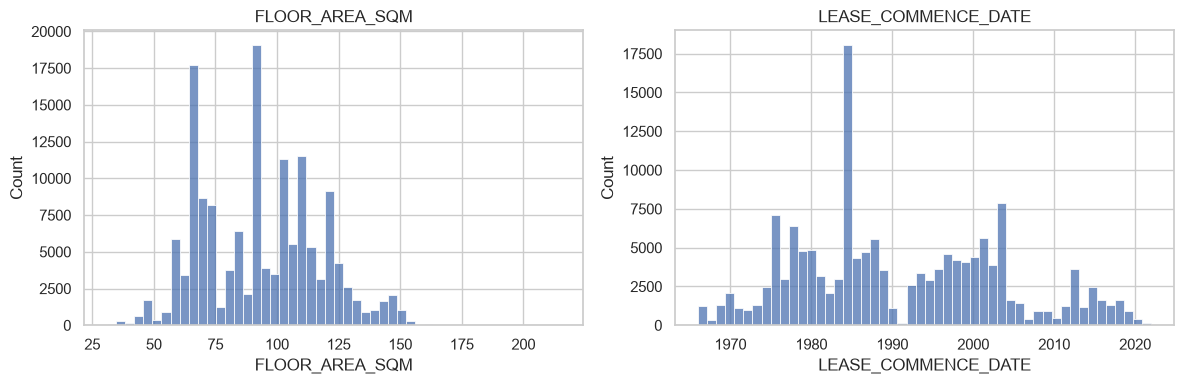

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['FLOOR_AREA_SQM'], bins=50, ax=axes[0])
axes[0].set_title('FLOOR_AREA_SQM')
sns.histplot(train['LEASE_COMMENCE_DATE'], bins=50, ax=axes[1])
axes[1].set_title('LEASE_COMMENCE_DATE')
plt.tight_layout()
plt.show()

## 5. Bivariate: predictor vs `MONTHLY_RENT`
Which raw features carry the most signal, and where's the obvious collinearity (e.g. FLAT_TYPE vs FLOOR_AREA_SQM).

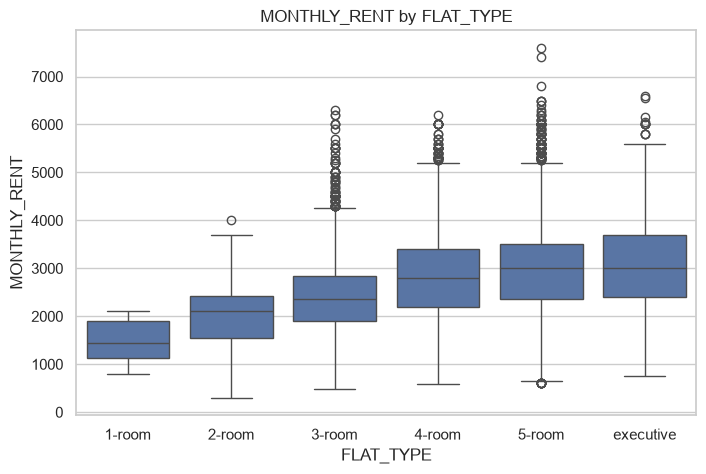

In [60]:
flat_type_order = ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=train, x='FLAT_TYPE', y='MONTHLY_RENT', order=flat_type_order, ax=ax)
ax.set_title('MONTHLY_RENT by FLAT_TYPE')
plt.show()

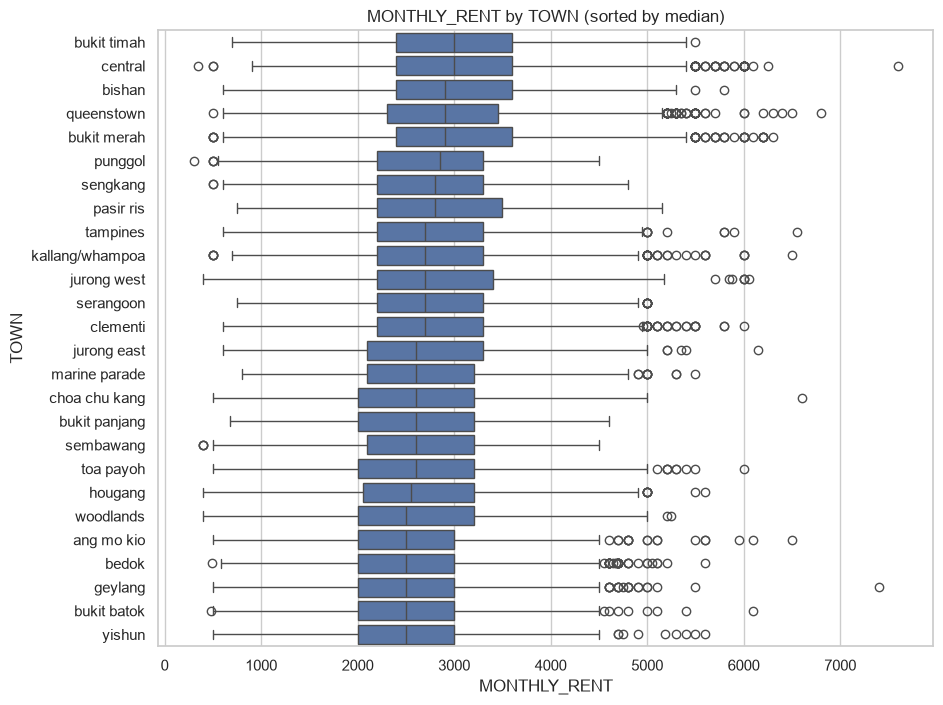

In [61]:
town_order = train.groupby('TOWN')['MONTHLY_RENT'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 8))
sns.boxplot(data=train, y='TOWN', x='MONTHLY_RENT', order=town_order, ax=ax)
ax.set_title('MONTHLY_RENT by TOWN (sorted by median)')
plt.show()

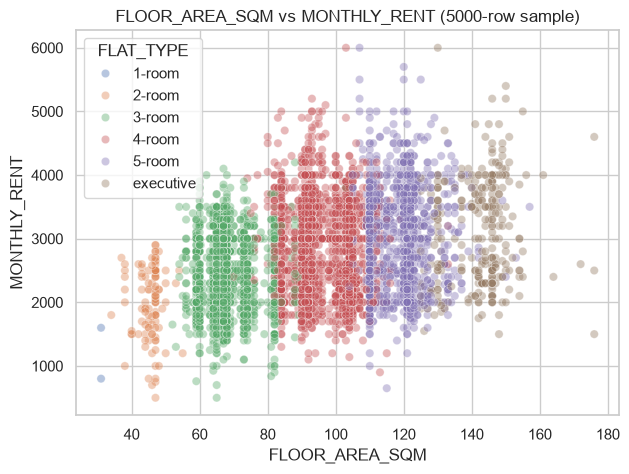

In [62]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=train.sample(5000, random_state=0), x='FLOOR_AREA_SQM', y='MONTHLY_RENT',
                 hue='FLAT_TYPE', hue_order=flat_type_order, alpha=0.4, ax=ax)
ax.set_title('FLOOR_AREA_SQM vs MONTHLY_RENT (5000-row sample)')
plt.show()

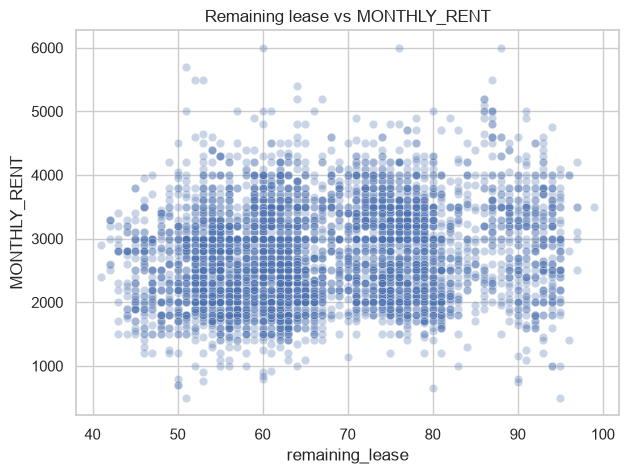

In [63]:
# Derived: remaining lease at the point of rental approval
for df in (train, test):
    df['approval_year'] = df['RENT_APPROVAL_DATE'].str.slice(0, 4).astype(int)
    df['remaining_lease'] = 99 - (df['approval_year'] - df['LEASE_COMMENCE_DATE'])

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=train.sample(5000, random_state=0), x='remaining_lease', y='MONTHLY_RENT', alpha=0.3, ax=ax)
ax.set_title('Remaining lease vs MONTHLY_RENT')
plt.show()

## 6. Temporal analysis
train and test dates barely overlap (train: 2021-01 to 2025-03, test: 2025-03 to 2026-07) — this is effectively a forecasting problem. Check the trend, and confirm the gap.

In [64]:
print('train RENT_APPROVAL_DATE range:', train['RENT_APPROVAL_DATE'].min(), '->', train['RENT_APPROVAL_DATE'].max())
print('test  RENT_APPROVAL_DATE range:', test['RENT_APPROVAL_DATE'].min(), '->', test['RENT_APPROVAL_DATE'].max())

train RENT_APPROVAL_DATE range: 2021-01 -> 2025-03
test  RENT_APPROVAL_DATE range: 2025-03 -> 2026-07


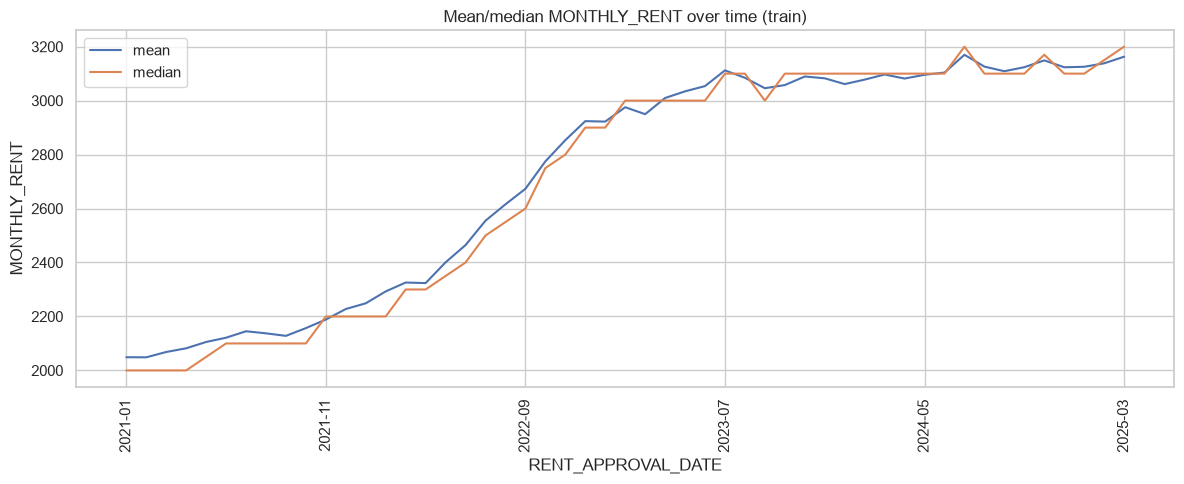

,mean,median,count
RENT_APPROVAL_DATE,,,
2024-04,3081.794024,3100.0,3146
2024-05,3095.840570,3100.0,3017
2024-06,3103.949186,3100.0,3011
2024-07,3169.898305,3200.0,3245
2024-08,3126.059301,3100.0,2833
2024-09,3108.928730,3100.0,2708
2024-10,3123.879459,3100.0,2663
2024-11,3149.154328,3170.0,2715
2024-12,3123.598757,3100.0,2896


In [65]:
monthly_rent_trend = train.groupby('RENT_APPROVAL_DATE')['MONTHLY_RENT'].agg(['mean', 'median', 'count']).sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
monthly_rent_trend['mean'].plot(ax=ax, label='mean')
monthly_rent_trend['median'].plot(ax=ax, label='median')
ax.set_title('Mean/median MONTHLY_RENT over time (train)')
ax.set_ylabel('MONTHLY_RENT')
ax.legend()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

monthly_rent_trend.tail(12)

In [66]:
# How much of train actually overlaps with test's date range? Informs a time-based validation split.
train_dates = pd.to_datetime(train['RENT_APPROVAL_DATE'] + '-01')
test_dates = pd.to_datetime(test['RENT_APPROVAL_DATE'] + '-01')

cutoff = train_dates.quantile(0.9)
print('Suggested time-based validation cutoff (last 10% of train by date):', cutoff)
print('Rows after cutoff (validation fold):', (train_dates >= cutoff).sum())

Suggested time-based validation cutoff (last 10% of train by date): 2024-10-01 00:00:00
Rows after cutoff (validation fold): 17198


## 7. Geospatial enrichment via `sg-hdb-block.csv`
Join on TOWN + BLOCK + STREET to bring in LATITUDE/LONGITUDE, MAX_FLOOR, YEAR_COMPLETED, PLANNING_AREA, REGION.
Check the join match rate first — a low rate signals a cleaning bug, not missing data.

In [67]:
hdb_block = pd.read_csv(f'{AUX_DIR}/sg-hdb-block.csv')
for c in ['TOWN', 'STREET', 'BLOCK']:
    hdb_block[c] = hdb_block[c].astype(str).str.strip().str.lower()

join_keys = ['TOWN', 'BLOCK', 'STREET']
hdb_block_dedup = hdb_block.drop_duplicates(subset=join_keys)

train_geo = train.merge(hdb_block_dedup, on=join_keys, how='left', suffixes=('', '_hdb'))
test_geo = test.merge(hdb_block_dedup, on=join_keys, how='left', suffixes=('', '_hdb'))

print('train join match rate:', train_geo['LATITUDE'].notna().mean())
print('test  join match rate:', test_geo['LATITUDE'].notna().mean())

unmatched = train_geo[train_geo['LATITUDE'].isna()][join_keys].drop_duplicates()
print('unmatched key combos (train), sample:')
unmatched.head(10)

train join match rate: 1.0
test  join match rate: 1.0
unmatched key combos (train), sample:


,TOWN,BLOCK,STREET


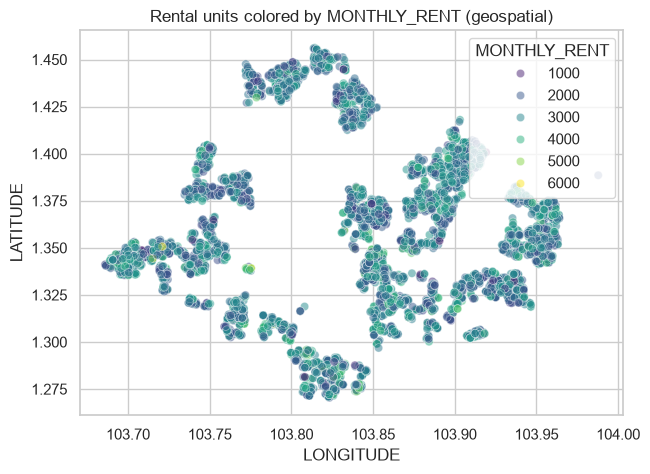

In [68]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=train_geo.dropna(subset=['LATITUDE']).sample(5000, random_state=0),
                 x='LONGITUDE', y='LATITUDE', hue='MONTHLY_RENT', palette='viridis', alpha=0.5, ax=ax)
ax.set_title('Rental units colored by MONTHLY_RENT (geospatial)')
plt.show()

## 8. Proximity/amenity features (MRT, schools, malls)
Compute distance to nearest MRT station / school / mall using the lat-long from step 7, then check correlation with MONTHLY_RENT before keeping the feature.

In [69]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def add_nearest_distance(df, poi_df, poi_lat='LATITUDE', poi_lon='LONGITUDE', out_col='dist_km'):
    """For each row in df (needs LATITUDE/LONGITUDE), find distance to nearest point in poi_df."""
    valid = df.dropna(subset=['LATITUDE', 'LONGITUDE'])
    dists = np.full(len(df), np.nan)
    lat_arr = poi_df[poi_lat].to_numpy()
    lon_arr = poi_df[poi_lon].to_numpy()
    for i, (lat, lon) in zip(valid.index, zip(valid['LATITUDE'], valid['LONGITUDE'])):
        d = haversine_km(lat, lon, lat_arr, lon_arr)
        dists[df.index.get_loc(i)] = d.min()
    df[out_col] = dists
    return df

In [70]:
mrt = pd.read_csv(f'{AUX_DIR}/sg-mrt-stations.csv')
schools = pd.read_csv(f'{AUX_DIR}/sg-schools.csv')
malls = pd.read_csv(f'{AUX_DIR}/sg-shopping-malls.csv')

train_geo = add_nearest_distance(train_geo, mrt, out_col='dist_mrt_km')
train_geo = add_nearest_distance(train_geo, schools, out_col='dist_school_km')
train_geo = add_nearest_distance(train_geo, malls, out_col='dist_mall_km')

train_geo[['dist_mrt_km', 'dist_school_km', 'dist_mall_km']].describe()

,dist_mrt_km,dist_school_km,dist_mall_km
count,150000.000000,150000.000000,150000.000000
mean,0.590872,0.345501,0.810213
std,0.326872,0.211975,0.447313
min,0.021845,0.024210,0.000026
25%,0.368029,0.202002,0.462382
50%,0.533264,0.294354,0.732250
75%,0.756432,0.433143,1.083308
max,2.571683,3.309216,3.202443


dist_mrt_km      -0.084662
dist_school_km   -0.001077
dist_mall_km     -0.083034
MONTHLY_RENT      1.000000
Name: MONTHLY_RENT, dtype: float64


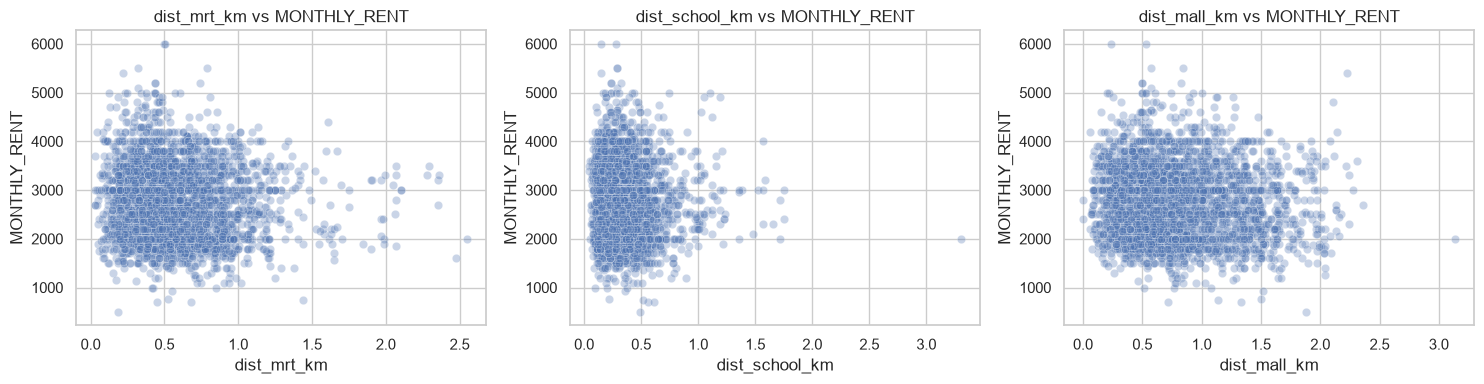

In [71]:
# Validate before trusting these features: correlation with MONTHLY_RENT
corr = train_geo[['dist_mrt_km', 'dist_school_km', 'dist_mall_km', 'MONTHLY_RENT']].corr()['MONTHLY_RENT']
print(corr)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['dist_mrt_km', 'dist_school_km', 'dist_mall_km']):
    sns.scatterplot(data=train_geo.dropna(subset=[col]).sample(3000, random_state=0),
                     x=col, y='MONTHLY_RENT', alpha=0.3, ax=ax)
    ax.set_title(f'{col} vs MONTHLY_RENT')
plt.tight_layout()
plt.show()

### 8b. Non-linear check: binning distance into ranges
Pearson correlation only catches straight-line relationships. Bin each distance into ranges and compare mean/median MONTHLY_RENT per bin to check for a threshold or non-monotonic effect the raw correlation could be missing.

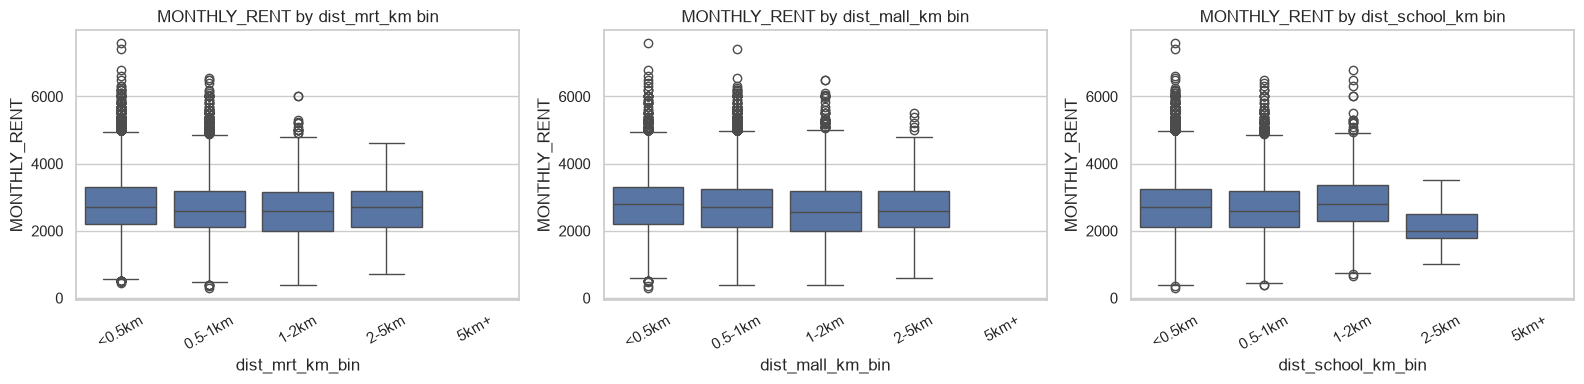

--- mean/median MONTHLY_RENT by dist_mrt_km_bin ---
                        mean  median  count
dist_mrt_km_bin                            
<0.5km           2786.915578  2700.0  68264
0.5-1km          2672.525244  2600.0  67500
1-2km            2612.627696  2600.0  13309
2-5km            2634.965480  2700.0    927

--- mean/median MONTHLY_RENT by dist_mall_km_bin ---
                         mean  median  count
dist_mall_km_bin                            
<0.5km            2795.986532  2800.0  42769
0.5-1km           2724.641260  2700.0  62937
1-2km             2634.611509  2550.0  42557
2-5km             2689.739206  2600.0   1737

--- mean/median MONTHLY_RENT by dist_school_km_bin ---
                           mean  median   count
dist_school_km_bin                             
<0.5km              2718.912484  2700.0  123966
0.5-1km             2704.903907  2600.0   23571
1-2km               2877.518288  2800.0    2406
2-5km               2144.385965  2000.0      57



In [72]:
dist_bins = [0, 0.5, 1, 2, 5, np.inf]
dist_labels = ['<0.5km', '0.5-1km', '1-2km', '2-5km', '5km+']

for col in ['dist_mrt_km', 'dist_mall_km', 'dist_school_km']:
    train_geo[f'{col}_bin'] = pd.cut(train_geo[col], bins=dist_bins, labels=dist_labels)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['dist_mrt_km', 'dist_mall_km', 'dist_school_km']):
    sns.boxplot(data=train_geo, x=f'{col}_bin', y='MONTHLY_RENT', ax=ax)
    ax.set_title(f'MONTHLY_RENT by {col} bin')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

for col in ['dist_mrt_km', 'dist_mall_km', 'dist_school_km']:
    print(f'--- mean/median MONTHLY_RENT by {col}_bin ---')
    print(train_geo.groupby(f'{col}_bin', observed=True)['MONTHLY_RENT'].agg(['mean', 'median', 'count']))
    print()

### 8c. Distance to a 'popular' school — what the dataset actually supports

`sg-schools.csv` has **no explicit popularity/ranking column**. The two candidate proxies from its real attributes are `MAINLEVEL_CODE` (school stage: primary/secondary/JC/mixed) and `TYPE_CODE` (funding/admission model: government school, government-aided sch, independent school, specialised independent school, specialised school).

`independent school` / `specialised independent school` are the closest thing to a brand-name/prestige flag in this data (e.g. Singapore's well-known independent schools). The cell below checks whether any of those overlap with `MAINLEVEL_CODE == primary` before using it as a proxy — if it does, we'll use TYPE_CODE + MAINLEVEL_CODE together as the 'popular primary school' filter; if not, we fall back to plain nearest-**primary**-school distance (using only `MAINLEVEL_CODE`), since Singapore's Primary 1 registration gives priority by home-to-school distance — that's the real mechanism linking school proximity to rental demand, independent of any single school's prestige.

In [73]:
schools_all = pd.read_csv(f'{AUX_DIR}/sg-schools.csv')
primary_schools = schools_all[schools_all['MAINLEVEL_CODE'].str.contains('primary', case=False, na=False)]

# sanity-check the 'popular school' idea (TYPE_CODE) before relying on it
popular_candidates = primary_schools[primary_schools['TYPE_CODE'].isin(
    ['independent school', 'specialised independent school'])]
print('Primary schools total:', len(primary_schools))
print('Primary schools also flagged independent/specialised-independent:', len(popular_candidates))
print('TYPE_CODE breakdown within primary schools:')
print(primary_schools['TYPE_CODE'].value_counts())

Primary schools total: 179
Primary schools also flagged independent/specialised-independent: 0
TYPE_CODE breakdown within primary schools:
TYPE_CODE
government school       136
government-aided sch     43
Name: count, dtype: int64


dist_primary_school_km   -0.005138
dist_school_km           -0.001077
MONTHLY_RENT              1.000000
Name: MONTHLY_RENT, dtype: float64


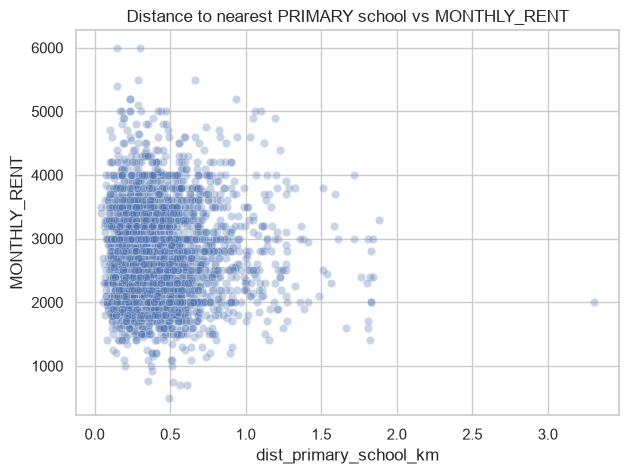

In [74]:
# No popularity signal survives at primary level (0 independent primary schools) -> use nearest-PRIMARY-school
# distance instead. Attribute used: MAINLEVEL_CODE only (filtered to rows containing 'primary').
train_geo = add_nearest_distance(train_geo, primary_schools, out_col='dist_primary_school_km')

corr_primary = train_geo[['dist_primary_school_km', 'dist_school_km', 'MONTHLY_RENT']].corr()['MONTHLY_RENT']
print(corr_primary)

fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=train_geo.dropna(subset=['dist_primary_school_km']).sample(3000, random_state=0),
                 x='dist_primary_school_km', y='MONTHLY_RENT', alpha=0.3, ax=ax)
ax.set_title('Distance to nearest PRIMARY school vs MONTHLY_RENT')
plt.show()

## 9. Macro auxiliary data: `sg-coe-prices.csv` and `sg-stock-prices.csv`
These aren't per-property — treat them as *candidate* monthly economic indicators and test correlation with the rent trend before including them.

In [75]:
coe = pd.read_csv(f'{AUX_DIR}/sg-coe-prices.csv')
coe['QUOTA_PREMIUM'] = coe['QUOTA_PREMIUM'].replace('[$,]', '', regex=True).astype(float)
coe_monthly = coe.groupby(['YEAR', 'MONTH'])['QUOTA_PREMIUM'].mean().reset_index()
print(coe_monthly.head())

stocks = pd.read_csv(f'{AUX_DIR}/sg-stock-prices.csv')
stocks['DATE'] = pd.to_datetime(stocks['DATE'])
stocks['year_month'] = stocks['DATE'].dt.strftime('%Y-%m')
stock_monthly = stocks.groupby('year_month')['ADJUSTED_CLOSE'].mean().reset_index()
print(stock_monthly.head())

   YEAR MONTH  QUOTA_PREMIUM
0  2021   apr      50396.750
1  2021   aug      51997.375
2  2021   dec      66886.250
3  2021   feb      44871.000
4  2021   jan      45187.375
  year_month  ADJUSTED_CLOSE
0    2021-01       10.182588
1    2021-02       11.610497
2    2021-03       11.040180
3    2021-04       11.994201
4    2021-05       11.952724


Correlation: mean MONTHLY_RENT vs mean ADJUSTED_CLOSE (monthly):
                    mean  ADJUSTED_CLOSE
mean            1.000000        0.026263
ADJUSTED_CLOSE  0.026263        1.000000


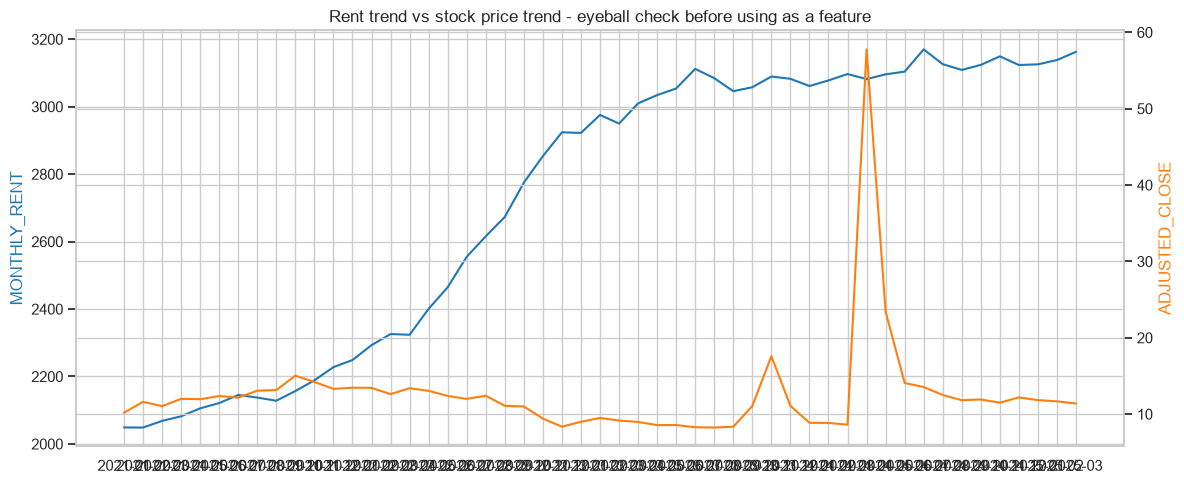

In [76]:
# Align stock index to train's monthly rent trend and check correlation
trend = monthly_rent_trend.reset_index().rename(columns={'RENT_APPROVAL_DATE': 'year_month'})
merged_macro = trend.merge(stock_monthly, on='year_month', how='left')

print('Correlation: mean MONTHLY_RENT vs mean ADJUSTED_CLOSE (monthly):')
print(merged_macro[['mean', 'ADJUSTED_CLOSE']].corr())

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(merged_macro['year_month'], merged_macro['mean'], color='tab:blue', label='mean MONTHLY_RENT')
ax1.set_ylabel('MONTHLY_RENT', color='tab:blue')
ax2 = ax1.twinx()
ax2.plot(merged_macro['year_month'], merged_macro['ADJUSTED_CLOSE'], color='tab:orange', label='stock ADJUSTED_CLOSE')
ax2.set_ylabel('ADJUSTED_CLOSE', color='tab:orange')
plt.xticks(rotation=90)
plt.title('Rent trend vs stock price trend - eyeball check before using as a feature')
plt.tight_layout()
plt.show()

## 10. Outlier / anomaly review
Check whether extreme MONTHLY_RENT values are plausible given FLAT_TYPE/FLOOR_AREA_SQM, or data errors.

In [77]:
q_low, q_high = train['MONTHLY_RENT'].quantile([0.001, 0.999])
print('0.1%/99.9% MONTHLY_RENT bounds:', q_low, q_high)

extreme = train[(train['MONTHLY_RENT'] <= q_low) | (train['MONTHLY_RENT'] >= q_high)]
print(f'{len(extreme)} rows in the extreme 0.2% tail')
extreme[['TOWN', 'FLAT_TYPE', 'FLOOR_AREA_SQM', 'MONTHLY_RENT']].sort_values('MONTHLY_RENT')

0.1%/99.9% MONTHLY_RENT bounds: 724.9749999999999 5400.0
316 rows in the extreme 0.2% tail


,TOWN,FLAT_TYPE,FLOOR_AREA_SQM,MONTHLY_RENT
48007,punggol,2-room,46.0,300
24543,central,2-room,54.0,350
142876,hougang,2-room,38.0,400
47826,woodlands,2-room,45.0,400
9563,sembawang,2-room,46.0,400
...,...,...,...,...
90975,tampines,executive,152.0,6550
82064,choa chu kang,executive,215.0,6600
100082,queenstown,5-room,147.0,6800
96685,geylang,5-room,113.0,7400


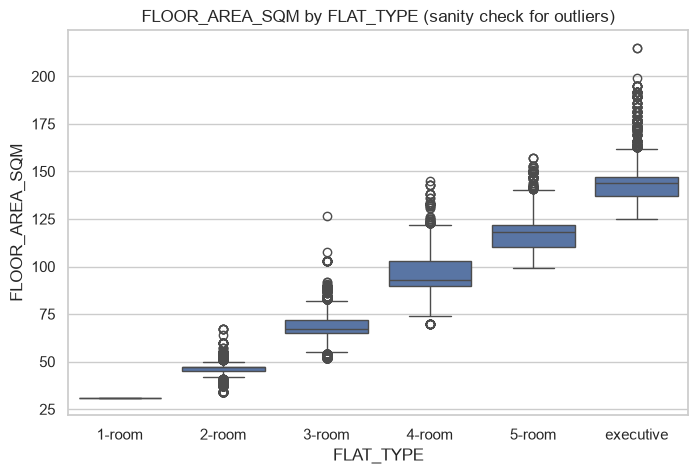

In [78]:
# Cross-check: does FLAT_TYPE roughly predict FLOOR_AREA_SQM range as expected? Flag mismatches.
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=train, x='FLAT_TYPE', y='FLOOR_AREA_SQM', order=flat_type_order, ax=ax)
ax.set_title('FLOOR_AREA_SQM by FLAT_TYPE (sanity check for outliers)')
plt.show()

## 11. Multicollinearity check
Quantify redundancy between FLAT_TYPE (as ordinal), FLOOR_AREA_SQM, and (once joined) MAX_FLOOR/YEAR_COMPLETED.

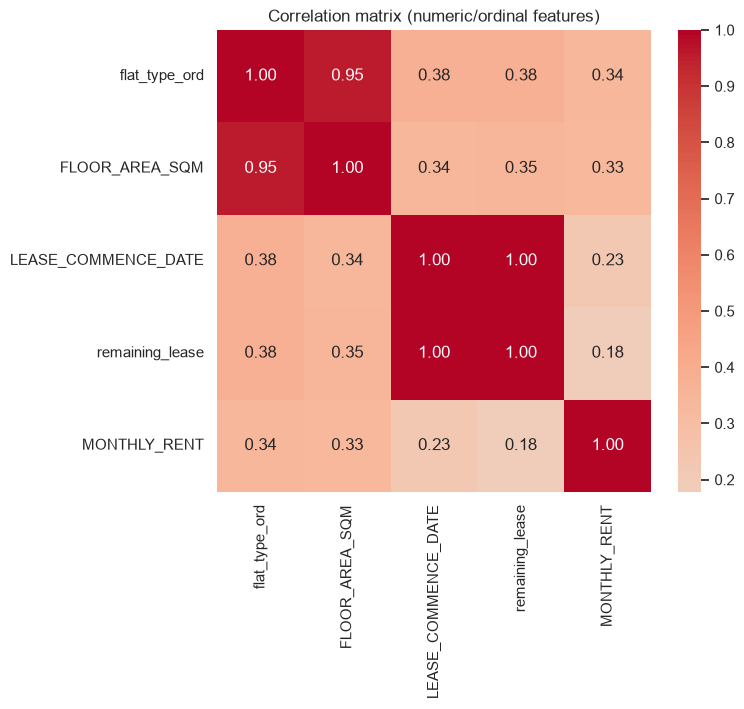

In [79]:
flat_type_rank = {t: i for i, t in enumerate(flat_type_order)}
train['flat_type_ord'] = train['FLAT_TYPE'].map(flat_type_rank)

num_feats = ['flat_type_ord', 'FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 'remaining_lease', 'MONTHLY_RENT']
corr_matrix = train[num_feats].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation matrix (numeric/ordinal features)')
plt.show()

## 12. Train/test distribution shift
After cleanup, compare category/feature distributions between train and test to catch covariate shift beyond the date gap already found in step 6 — this should shape the validation split.

In [80]:
for col in ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL']:
    train_dist = train[col].value_counts(normalize=True).rename('train')
    test_dist = test[col].value_counts(normalize=True).rename('test')
    comp = pd.concat([train_dist, test_dist], axis=1).fillna(0)
    comp['abs_diff'] = (comp['train'] - comp['test']).abs()
    print(f'--- {col}: top shifted categories ---')
    print(comp.sort_values('abs_diff', ascending=False).head(5))
    print()

--- TOWN: top shifted categories ---
                train     test  abs_diff
TOWN                                    
bukit batok  0.037367  0.04114  0.003773
jurong west  0.069880  0.07326  0.003380
bedok        0.059380  0.05606  0.003320
woodlands    0.050513  0.04770  0.002813
bishan       0.022040  0.01964  0.002400

--- FLAT_TYPE: top shifted categories ---
              train     test  abs_diff
FLAT_TYPE                             
2-room     0.020653  0.02872  0.008067
5-room     0.236820  0.23060  0.006220
executive  0.054893  0.05104  0.003853
3-room     0.326827  0.32850  0.001673
4-room     0.360527  0.36090  0.000373

--- FLAT_MODEL: top shifted categories ---
                   train     test  abs_diff
FLAT_MODEL                                 
model a         0.284967  0.29846  0.013493
new generation  0.182533  0.17758  0.004953
improved        0.293387  0.28858  0.004807
2 room          0.001493  0.00470  0.003207
simplified      0.045293  0.04282  0.002473



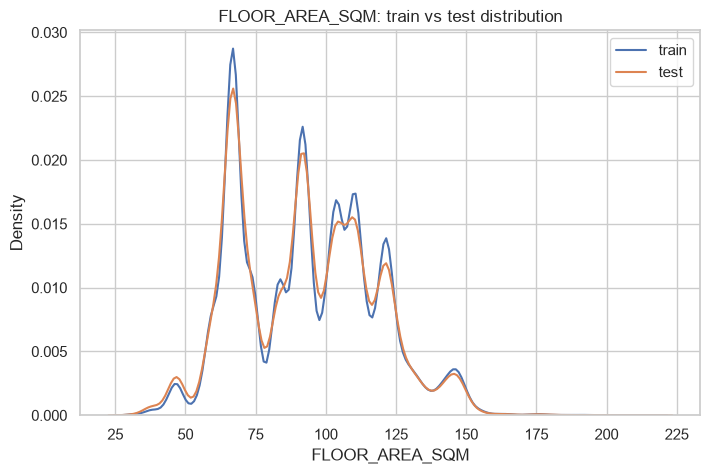

In [81]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(train['FLOOR_AREA_SQM'], label='train', ax=ax)
sns.kdeplot(test['FLOOR_AREA_SQM'], label='test', ax=ax)
ax.set_title('FLOOR_AREA_SQM: train vs test distribution')
ax.legend()
plt.show()